### Libraries and Plot Settings

In [22]:
import numpy as np
from numba import njit, prange
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


### Inversion Method

<div style="text-align: justify; text-justify: inter-word; font-size: 18px;">

The Inverse Transform Sampling method is a technique used to generate samples of a random variable $X$ following a desired probability density function (PDF) $f(x)$. Suppose $U$ is a uniformly distributed random variable on the interval $[0,1]$, namely $U \sim \mathrm{Uniform}(0,1)$. Samples of $X$ can then be generated by applying the inverse cumulative distribution function (CDF) $F^{-1}$ to $U$, provided that the inverse exists, such that $X=F^{-1}(U)$.

In our 2D example, the desired PDF along the $x$-axis is $f(x)=\pi\sin(2\pi x)$, where $0\leq x\leq0.5$ and $\pi$ is the normalization constant. Applying the inversion method, the source position along the $x$-axis is given by $X=\frac{\cos^{-1}(1-2U)}{2\pi}$. Along the $y$-axis, source positions follow a uniform distribution over the interval $[0.1,0.9]$.

This distribution was selected because it is not directly available as a predefined sampling distribution in either *numpy.random* or *scipy.stats*.

</div>


In [2]:
def F(): return np.random.uniform()
ns = 30
x_sources = [np.arccos(1-2*F())/(2*np.pi) for _ in range(ns)]
y_sources = np.random.uniform(0.1,0.9,ns)

### Set up physical and numerical parameters

In [3]:
L = 1.0          # Length of the square computational domain [0,L] x [0,L]
T = 5.0          # Final simulation time

a = 0.005        # Diffusion coefficient
dx = dy = 0.01   # Spatial step sizes in x and y directions
dt = 0.0005      # Time step
U = 0.7          # Constant advection velocity in the x-direction

# Dimensionless advection and diffusion numbers
c = U * dt / dx
r = (a * dt) / (dx**2)

if 5*r + 2*c > 1: raise ValueError("Stability condition violated: 5*r + 2*c <= 1")

# Computational grids

nx = int(round(L/dx))
ny = int(round(L/dy))

x = (np.arange(nx) + 0.5)*dx
y = (np.arange(ny) + 0.5)*dy
t = np.arange(0,T+dt,dt)

# --- Temperature fields ---


u_old = np.zeros((ny,nx))            # u_old stores the temperature field at the current time step

u_new = np.zeros_like(u_old)         # u_new stores the updated temperature field at the next time step

# --- Saving field ---

save_every = 2
n_save = (len(t) - 1) // save_every + 1
u_saved = np.zeros((n_save,ny,nx))
u_saved[0, :, :] = u_old.copy()                        # Store initial condition

### Source Fields
<div style="text-align: justify; text-justify: inter-word; font-size: 18px;">

The source activation is modeled as a discrete-time approximation of a Poisson process. At each time step, every inactive source has probability $\lambda \Delta t$ of becoming active, where $\lambda$ is the firing rate. Therefore, the number of activations over a fixed time interval follows a Poisson distribution, while the waiting times between activations are exponentially distributed.

</div>

In [4]:
# --- active[k] indicates whether source k is currently injecting ---

active = np.zeros(ns,dtype=np.int64)   # 0 = inactive, 1 = active

# --- remaining[k] stores how much injection time is left for source k ---

remaining = np.zeros(ns)

# --- Total source term at the current time step ---

source = np.zeros_like(u_old)
rate = 0.5                              # Poisson firing rate

# --- q[k,j,i] stores the spatial Gaussian profile of source k ---

q = np.zeros((ns, ny, nx))
for k in range(ns):
    for i in range(nx):
        for j in range(ny):

            # Squared distance from source k in x and y directions
            argx = ((x[i] - x_sources[k])**2) / 0.005**2
            argy = ((y[j] - y_sources[k])**2) / 0.005**2

            # Gaussian source profile.
            q[k, j, i] = 1000*np.exp(-argx -argy)

## Discretization (FVM/FDM)

<div style="text-align: justify;text-justify: inter-word; font-size: 18px;">

$\frac{\partial{u_p}}{\partial{t}}$ = $a\left ( { \frac{u_E -2 u_P + u_W}{Δx^2}} \right)$ + $a\left ( { \frac{u_N -2 u_P + u_S}{Δy^2}} \right)$ - $U \left({\frac{u_P - u_W}{Δx}}\right) + Q_P$ </br>

After transforming to Cartesian indexing, the above expression yields a finite difference scheme (FDM), where the diffusion term is approximated using a central difference scheme (CDS) and the advection term using a backward difference scheme.</br>

For the time discretization, an explicit time-stepping scheme is used: $ u_{i,j}^{n+1} = u_{i,j}^{n} + r\left({u_{i+1,j}^n - 2u_{i,j}^n + u_{i-1,j}^n}\right) + r\left({u_{i,j+1}^n - 2u_{i,j}^n + u_{i,j-1}^n}\right) - c\left({u_{i,j}^n - u_{i-1,j}^n}\right) + Δt Q_{i,j}^n$ </br>

where $i,j=0,1,...,N$ and $Δx=Δy, \:$ leading to a single diffusion parameter  $r=a\frac{Δt}{Δx^2}$ and $c = U \frac{Δt}{Δx}.$

#### *Boundary conditions*

On the top, bottom and right boundaries, Neumann Boundary Conditions are imposed: $\left({\frac{\partial{u}}{\partial{x}}}\right)_s =0$, where $s=e,n,s \:$ </br>

 while at the left boundary the themperature is fixed at zero (Dirichlet condition) $u_w = 0.$ </br>

Linear interpolation is applied at all boundaries, and ghost points are introduced. For the Neumann boundary conditions, the resulting expressions are equivalent to those obtained by directly applying the finite difference method (FDM):

$u_{i,j-1}=u_{i,j},\; u_{i,j+1}=u_{i,j},\; u_{i+1,j}=u_{i,j}\;$</br>

which yield three individual equations for the three sides, with the ghost points eliminated. Similarly, two additional equations are derived for the upper-right and bottom-right corners using:
$u_{i+1,j-1}=u_{i,j}\;$ and $\;u_{i+1,j+1}=u_{i,j}.$ </br>

For the Dirichlet boundary condition, linear interpolation leads to: $u_{i-1,j}=-u_{i,j}$ which is used to eliminate the ghost points in the discretized equation along the left boundary. Consequently, two additional equations are obtained for the upper-left and bottom-left corners
</div>

In [5]:
@njit(parallel=True)
def FTCS(dt, ns, u_old, u_new, u_history, source, c, r, nt, ny, nx, save_every, active, remaining, rate, q):

    injection_time = 0.1
    save_idx = 1
    for n in range(1, nt):
      source[:, :] = 0.0
      for k in range(ns):
            if active[k] == 0:

                  if np.random.rand() < rate * dt:
                        active[k] = 1
                        remaining[k] = injection_time

            if active[k] == 1:
                  source += q[k]
                  remaining[k] -= dt

                  if remaining[k] <= 0.0:
                        active[k] = 0

      # --- PDE solving - Interior ---

      for j in prange(1,ny-1):
           for i in range(1,nx-1):
                u_new[j,i] = (1.0 - 4.0*r - c)*u_old[j,i] + (r+c)*u_old[j,i-1] + r*(u_old[j,i+1] + u_old[j-1,i] + u_old[j+1,i]) + dt*source[j,i]

      # --- Top and Bottom Boundaries ---

      for i in range(1,nx-1):

            # Top (y=L) - Neumann
            u_new[ny-1,i] = (1.0 - 3.0*r - c)*u_old[ny-1,i] + (r+c)*u_old[ny-1,i-1] + r*(u_old[ny-1,i+1] + u_old[ny-2,i])

            # Bottom (y=0) - Neumann
            u_new[0,i] = (1.0 - 3.0*r - c)*u_old[0,i] + (r+c)*u_old[0,i-1] + r*(u_old[0,i+1] + u_old[1,i])

      # --- Left and Right Boundaries ---

      for j in range(1,ny-1):

          # Right (x=L) - Neumann
          u_new[j,nx-1] = (1.0 - 3.0*r - c)*u_old[j,nx-1] + (r+c)*u_old[j,nx-2] + r*(u_old[j-1,nx-1] + u_old[j+1,nx-1])

          # Left (x=0) - Dirichlet
          u_new[j,0] = (1.0 - 5.0*r - 2.0*c)*u_old[j,0] + r*(u_old[j,1] + u_old[j-1,0] + u_old[j+1,0])

      # --- Four Corners ---

      # Bottom-left (Dirichlet + Neumann)
      u_new[0,0] = (1.0 - 4.0*r - 2.0*c)*u_old[0,0] + r*(u_old[0,1] + u_old[1,0])

      # Top-left (Dirichlet + Neumann)
      u_new[ny-1,0] = (1.0 - 4.0*r - 2.0*c)*u_old[ny-1,0] + r*(u_old[ny-1,1] + u_old[ny-2,0])

      # Bottom-right (Neumann + Neumann)
      u_new[0,nx-1] = (1.0 - 2.0*r - c)*u_old[0,nx-1] + (r+c)*u_old[0,nx-2] + r*u_old[1,nx-1]

      # Top-right (Neumann + Neumann)
      u_new[ny-1,nx-1] = (1.0 - 2.0*r - c)*u_old[ny-1,nx-1] + (r+c)*u_old[ny-1,nx-2] + r*u_old[ny-2,nx-1]

      # --- Update ---

      u_old,u_new=u_new,u_old

            # --- Save ---

      if n % save_every == 0:
        u_history[save_idx,:,:] = np.copy(u_old)
        save_idx += 1
    return u_history

u_final=FTCS(dt,ns,u_old,u_new,u_saved,source,c,r,len(t),len(y),len(x),save_every,active,remaining,rate,q)
#FTCS.parallel_diagnostics(level=2)

# Animation (Plotly)

In [ ]:
frames=[]
for k in range(1,len(u_final[:,0,0]),2):

    f_plot=u_final[k].copy()
    frames.append(go.Frame(data=[go.Heatmap(x=x,y=y,z=f_plot,zsmooth="best",colorscale="Jet",zmin=0,zmax=0.5,
                                            colorbar=dict(yanchor="middle",len=425,lenmode="pixels"))]))

f0=u_final[0,:,:].copy()

fig=go.Figure(data=[go.Heatmap(x=x,y=y,z=f0,colorscale="Jet",zsmooth="best",zmin=0,zmax=0.5,
                               colorbar=dict(yanchor="middle",len=425,lenmode="pixels"))],

    layout=go.Layout(updatemenus=[dict(x=0.1,y=-0.12,xanchor="center",direction="left",type="buttons", showactive=False,

        buttons=[dict(label="Play", method="animate",
                      args=[None, dict(frame=dict(duration=50,redraw=True),transition=dict(duration=0),fromcurrent=True,mode="immediate")]),
                 dict(label="Pause",method="animate",
                      args=[[None], dict(frame=dict(duration=50,redraw=False),transition=dict(duration=0),mode="immediate")])])]),frames=frames)

fig.update_layout(title=dict(text="Heat Sources Temperature",x=0.5,y=0.925,
                             font=dict(family="Linux Libertine O",color="Black",size=30)),
                             width=800,height=600,plot_bgcolor="White",
                             xaxis_title="x",xaxis_title_font=dict(color="black",size=30,family="Linux Libertine O"),
                             yaxis_title="y",yaxis_title_font=dict(color="black",size=30,family="Linux Libertine O"))

fig.update_xaxes(range=[0,1],linecolor="black",showline=True,mirror=True,
                 tickfont=dict(size=20,color="black"), ticks="outside", ticklen=8, tickwidth=2)
fig.update_yaxes(range=[0,1],linecolor="black",showline=True,mirror=True,
                 tickfont=dict(size=20,color="black"), ticks="outside", ticklen=8, tickwidth=2)

fig.show(auto_play=False)
fig.write_html("Animation.html",auto_play=False,include_plotlyjs="cdn")

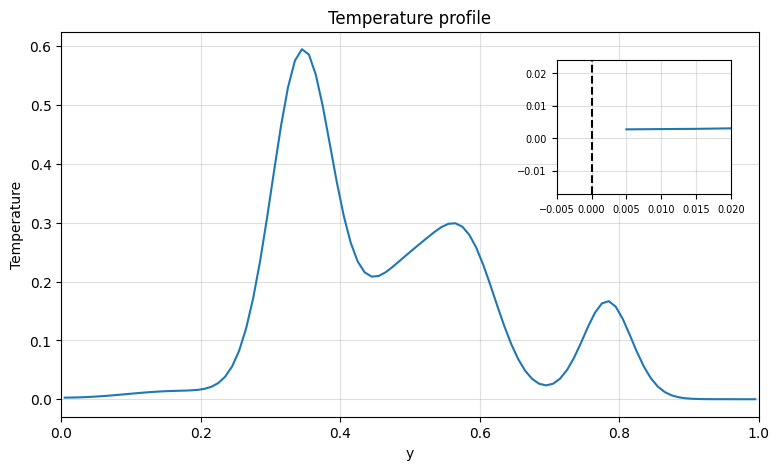

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

# Main temperature profile
ax.plot(y, u_final[1000,:,50])

ax.set_xlabel('y')
ax.set_xlim([0,1])
ax.set_ylabel('Temperature')
ax.set_title('Temperature profile')
ax.grid(True,alpha=0.4)

# Zoomed inset (bottom-left)
ax_zoom = inset_axes(ax,width="25%",height="35%",loc="upper right",borderpad=2)

ax_zoom.plot(y, u_final[1000,:,50])
ax_zoom.axvline(0, color='k', linestyle='--')

# Zoom into the gap between x=0 and x=dx/2
ax_zoom.set_xlim(-0.005, 0.02)
ax_zoom.set_ylim(min(u_final[1000,:5,50]) - 0.02,max(u_final[1000,:5,50]) + 0.02)

ax_zoom.tick_params(axis="both", labelsize=7)
ax_zoom.grid(True,alpha=0.4)
plt.show()